# Personality recoverability — judge-prompt and turn-window ablation

Two objections to the personality-reconstruction result are tested here:

1. **Circularity.** The judge prompt used in the paper (*anchored*) spells out behavioral criteria per HEXACO level that paraphrase the persona-generating prompts, so recovery could reflect wording overlap between the two prompts rather than patient behavior.
2. **Surface visibility.** Recovery could be carried by persona cues that surface in the opening turns and are not sustained.

We re-score the stored `patient_comparison_vha` conversations with **Gemini 3.1 Flash-Lite** (the paper's judge) under two judge prompts

- **anchored** — the paper's prompt, with per-level behavioral criteria;
- **neutral** — *"Recover the HEXACO personality axes of the patient"*, giving only the axis name and its scale direction and sharing no wording with the persona-generating prompts;

on three transcript windows: the **full** conversation, **turns 1–10**, and **turns 11–20**.

The headline metric is the one of the extreme-personality study: the mean absolute difference between the reconstructed level and the configured parametrization (manipulated axis at 3, the remaining axes at 1), per simulator and axis. Scores are produced by `scripts/run_personality_ablation.py`.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import logging

os.chdir("..")
logging.getLogger().setLevel(logging.WARNING)

In [2]:
import pandas as pd

from patient_simulator.misc.personality_ablation import (
    axis_recovery,
    judge_agreement,
    manipulated_axis_contrast,
    overall_recovery,
    to_long,
    window_agreement,
)
from patient_simulator.misc.plotting import (
    hexaco_distance_to_truth,
    plot_personality_extreme_difference,
    plot_personality_recovery_ablation,
)

ROOT = "results/patient_comparison_vha"

VARIANT_LABELS = {
    "anchored": "Anchored judge prompt (paper)",
    "neutral": "Neutral judge prompt (ablation)",
}
WINDOW_LABELS = {
    "full": "Full conversation",
    "turns_1_10": "Turns 1-10",
    "turns_11_20": "Turns 11-20",
}

# Extreme-personality pairings of the paper: each persona drives one axis to 3
PERSONA_AXIS_MAP = {
    "PatientsWithPersonality_H3_E1_X1_A1_C1_O1_LB": "H",
    "PatientsWithPersonality_H1_E3_X1_A1_C1_O1_LB": "E",
    "PatientsWithPersonality_H1_E1_X3_A1_C1_O1_LB": "X",
    "PatientsWithPersonality_H1_E1_X1_A3_C1_O1_LB": "A",
    "PatientsWithPersonality_H1_E1_X1_A1_C3_O1_LB": "C",
    "PatientsWithPersonality_H1_E1_X1_A1_C1_O3_LB": "O",
    "PatientSimPatient_persdistrust_cefrB_dazednormal_recalllow": "H",
    "PatientSimPatient_persoveranxious_cefrB_dazednormal_recallhigh": "E",
    "PatientSimPatient_persverbose_cefrB_dazednormal_recallhigh": "X",
    "PatientSimPatient_persimpatient_cefrB_dazednormal_recallhigh": "A",
    "PatientSimPatient_persplain_cefrB_dazedhigh_recalllow": "C",
    "PatientSimPatient_persdistrust_cefrB_dazednormal_recallhigh": "O",
}

## 1. Load

`scores` holds one row per (run × window × judge prompt) with the six reconstructed levels. `extremes` reshapes the single-axis personas into the frame `hexaco_distance_to_truth` expects, with `rater` carrying the judge prompt. `long` holds one row per axis with the level configured in the PWP persona name, for the effect-size statistics in section 4.

In [3]:
scores = pd.read_csv(f"{ROOT}/personality_ablation.csv")

extremes = scores[scores["patient_name"].isin(PERSONA_AXIS_MAP)].copy()
extremes["hexaco_axis"] = extremes["patient_name"].map(PERSONA_AXIS_MAP)
extremes["patient_type"] = extremes["simulator"]
extremes["rater"] = extremes["prompt_variant"]
extremes = extremes.rename(
    columns={f"recon_{a}": f"personality_reconstructed_{a}" for a in "HEXACO"}
)

long = to_long(scores)
covered = set(scores.loc[scores["window"] == "turns_11_20", "conversation_name"])

print(
    f"{scores['conversation_name'].nunique()} conversations, "
    f"{len(covered)} of them >= 20 turns"
)
scores.groupby(["prompt_variant", "window"]).size().unstack()

30 conversations, 30 of them >= 20 turns


window,full,turns_11_20,turns_1_10
prompt_variant,,,
anchored,480,480,480
neutral,480,480,480


## 2. Main result — absolute difference to the configured parametrization

The metric of the extreme-personality table in the paper, recomputed under both judge prompts. The anchored/full rows reproduce the autorater row of the paper (which used the five study conversations; here all 30 VHA cases are scored).

Both claims of the paper survive the neutral judge: PWP stays close to its configured parametrization, and stays closer than PatientSim. Unlike the ACI-Bench run, the margin does not widen when the judge is de-anchored — on VHA the gap is flat at ≈ 0.305 under both prompts (PWP 0.472 → 0.726, PatientSim 0.777 → 1.031), so the de-anchoring claim must be stated as *robust*, not *strengthened*.

In [4]:
main = hexaco_distance_to_truth(extremes[extremes["window"] == "full"])
main.round(3)

axis                                  H      E      X      A      C      O  \
rater    patient_type                                                        
anchored PatientSim               0.167  1.278  1.450  0.717  0.461  0.589   
         PatientsWithPersonality  0.350  0.483  1.022  0.450  0.372  0.156   
neutral  PatientSim               0.667  1.328  0.889  0.667  1.006  1.633   
         PatientsWithPersonality  0.856  0.383  0.322  0.517  0.656  1.622   

axis                               mean  
rater    patient_type                    
anchored PatientSim               0.777  
         PatientsWithPersonality  0.472  
neutral  PatientSim               1.031  
         PatientsWithPersonality  0.726

In [5]:
gap = main.xs("PatientSim", level="patient_type") - main.xs(
    "PatientsWithPersonality", level="patient_type"
)
gap.round(3)

axis,H,E,X,A,C,O,mean
rater,,,,,,,
anchored,-0.183,0.794,0.428,0.267,0.089,0.433,0.305
neutral,-0.189,0.944,0.567,0.150,0.350,0.011,0.306


## 3. The same result restricted to turns 1–10 and turns 11–20

Turns 11–20 exist only for conversations of at least 20 turns. A window carrying no opening self-presentation recovers the configured personality as well as the opening one, under either judge prompt.

In [6]:
pd.concat(
    {
        window: hexaco_distance_to_truth(extremes[extremes["window"] == window])["mean"]
        for window in WINDOW_LABELS
    },
    axis=1,
).round(3)

full  turns_1_10  turns_11_20
rater    patient_type                                           
anchored PatientSim               0.777       0.758        0.721
         PatientsWithPersonality  0.472       0.442        0.452
neutral  PatientSim               1.031       0.936        0.951
         PatientsWithPersonality  0.726       0.687        0.644

In [7]:
window_agreement(
    long[long["conversation_name"].isin(covered)], "turns_1_10", "turns_11_20"
).set_index("prompt_variant").round(3)

,n,spearman,exact_match,within_one,mean_shift
prompt_variant,,,,,
anchored,2880,0.743,0.778,0.966,-0.036
neutral,2880,0.698,0.701,0.944,-0.032


## 4. Supporting effect sizes

Absolute differences are sensitive to the constant shift the neutral judge is free to introduce when it uses the 1–3 range with a different anchor (`bias` below). These statistics are invariant to it: `delta` is the mean reconstructed level at configured level 3 minus configured level 1, and `spearman` the rank correlation between configured and reconstructed level. Pooled over E, X, A, C, O across the 9 PWP personas, restricted to conversations covering all three windows.

In [8]:
paired = long[long["conversation_name"].isin(covered)].dropna(subset=["target"])

overall_recovery(paired[paired["axis"] != "H"]).set_index(["prompt_variant", "window"])[
    [
        "n",
        "spearman",
        "exact_match",
        "within_one",
        "mae",
        "bias",
        "delta",
        "cohens_d",
        "p",
    ]
].round(3)

,,n,spearman,exact_match,within_one,mae,bias,delta,cohens_d,p
prompt_variant,window,,,,,,,,,
anchored,full,1350,0.472,0.649,0.899,0.453,0.293,1.327,2.173,0.0
neutral,full,1350,0.290,0.536,0.763,0.701,0.498,0.936,1.186,0.0
anchored,turns_1_10,1350,0.434,0.673,0.930,0.397,0.139,1.146,1.748,0.0
neutral,turns_1_10,1350,0.249,0.537,0.811,0.652,0.370,0.800,1.014,0.0
anchored,turns_11_20,1350,0.414,0.650,0.934,0.416,0.124,0.971,1.504,0.0
neutral,turns_11_20,1350,0.291,0.550,0.840,0.610,0.346,0.837,1.103,0.0


In [9]:
axis_stats = axis_recovery(paired)
axis_stats.pivot_table(
    index="axis", columns=["prompt_variant", "window"], values="delta"
).round(2)

prompt_variant anchored                        neutral                       
window             full turns_11_20 turns_1_10    full turns_11_20 turns_1_10
axis                                                                         
A                  1.24        0.86       0.65    1.34        1.16       1.12
C                  1.39        0.80       1.13    1.13        1.19       1.26
E                  1.24        0.97       1.29    1.32        1.10       1.23
H                  0.17        0.28       0.02   -0.24        0.01      -0.39
O                  1.85        1.79       1.92   -0.11        0.12      -0.29
X                  0.83        0.37       0.66    1.11        0.70       0.78

In [10]:
axis_stats.set_index(["prompt_variant", "window", "axis"])[
    ["mean_low", "mean_high", "delta", "se", "cohens_d", "p", "spearman"]
].round(3)

,,,mean_low,mean_high,delta,se,cohens_d,p,spearman
prompt_variant,window,axis,,,,,,,
anchored,full,H,1.061,1.233,0.172,0.095,0.415,0.078,0.279
neutral,full,H,1.578,1.333,-0.244,0.128,-0.329,0.062,-0.161
anchored,turns_1_10,H,1.144,1.167,0.022,0.076,0.054,0.773,0.211
neutral,turns_1_10,H,1.589,1.200,-0.389,0.108,-0.575,0.001,-0.195
anchored,turns_11_20,H,1.122,1.400,0.278,0.135,0.482,0.048,0.188
neutral,turns_11_20,H,1.494,1.500,0.006,0.136,0.008,0.968,-0.045
anchored,full,E,1.362,2.600,1.238,0.105,1.928,0.000,0.528
neutral,full,E,1.314,2.633,1.319,0.137,2.004,0.000,0.582
anchored,turns_1_10,E,1.176,2.467,1.290,0.129,2.129,0.000,0.570


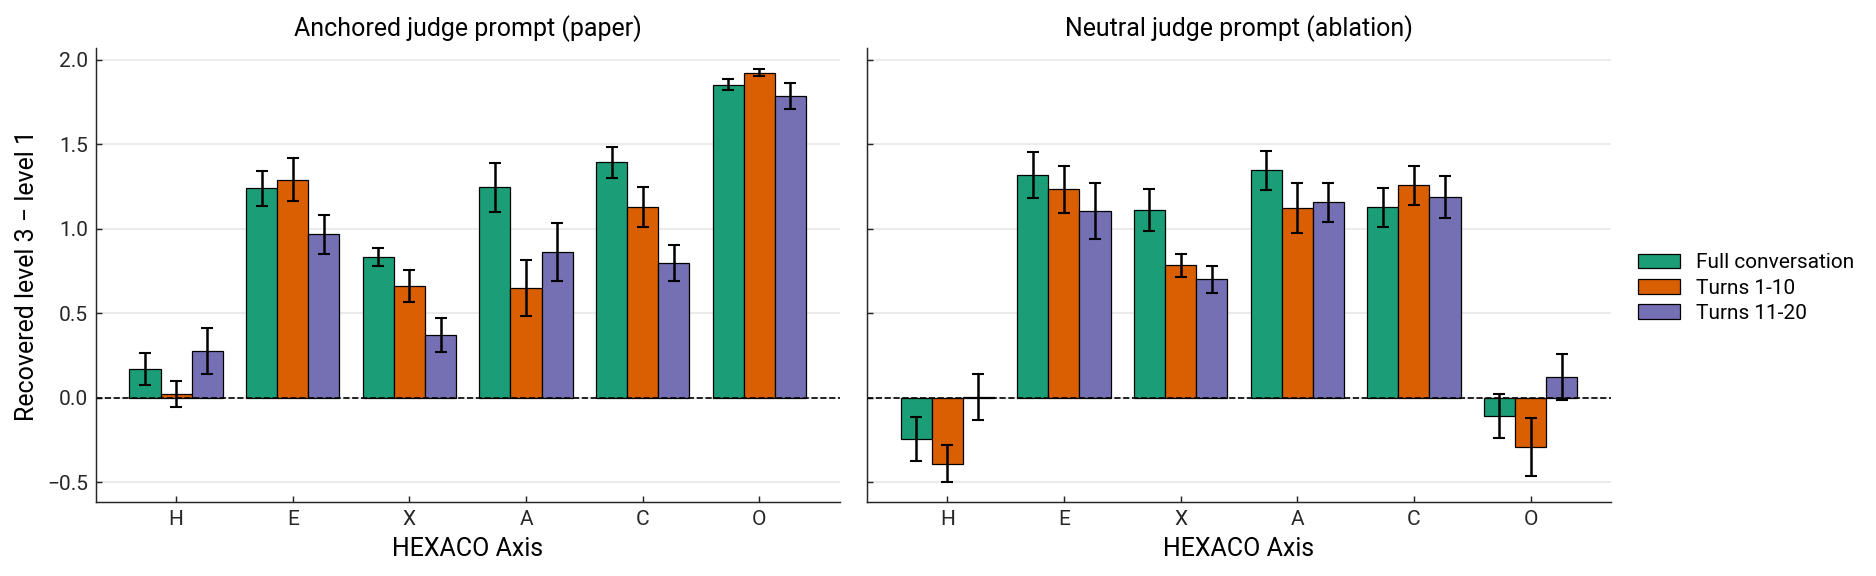

In [11]:
plot_personality_recovery_ablation(
    axis_stats,
    variant_labels=VARIANT_LABELS,
    window_labels=WINDOW_LABELS,
    save_as="personality_recovery_ablation",
);

## 5. Extreme-vs-low discrimination per simulator

The complementary view of section 2: for each single-axis persona, the reconstructed value on its manipulated axis minus the value the same simulator receives on that axis when it is *not* manipulated. Unlike the distance-to-target metric this is insensitive to how each judge anchors the scale, and it ranks the simulators the same way.

In [12]:
contrast = manipulated_axis_contrast(
    scores[scores["conversation_name"].isin(covered)], PERSONA_AXIS_MAP
)
contrast[~contrast["axis"].isin(["H", "C"])].groupby(
    ["prompt_variant", "window", "simulator"]
)["delta"].mean().unstack().round(3)

simulator                   PatientSim  PatientsWithPersonality
prompt_variant window                                          
anchored       full              0.763                    1.207
               turns_11_20       0.840                    0.942
               turns_1_10        0.782                    1.072
neutral        full              0.445                    0.853
               turns_11_20       0.545                    0.718
               turns_1_10        0.588                    0.662

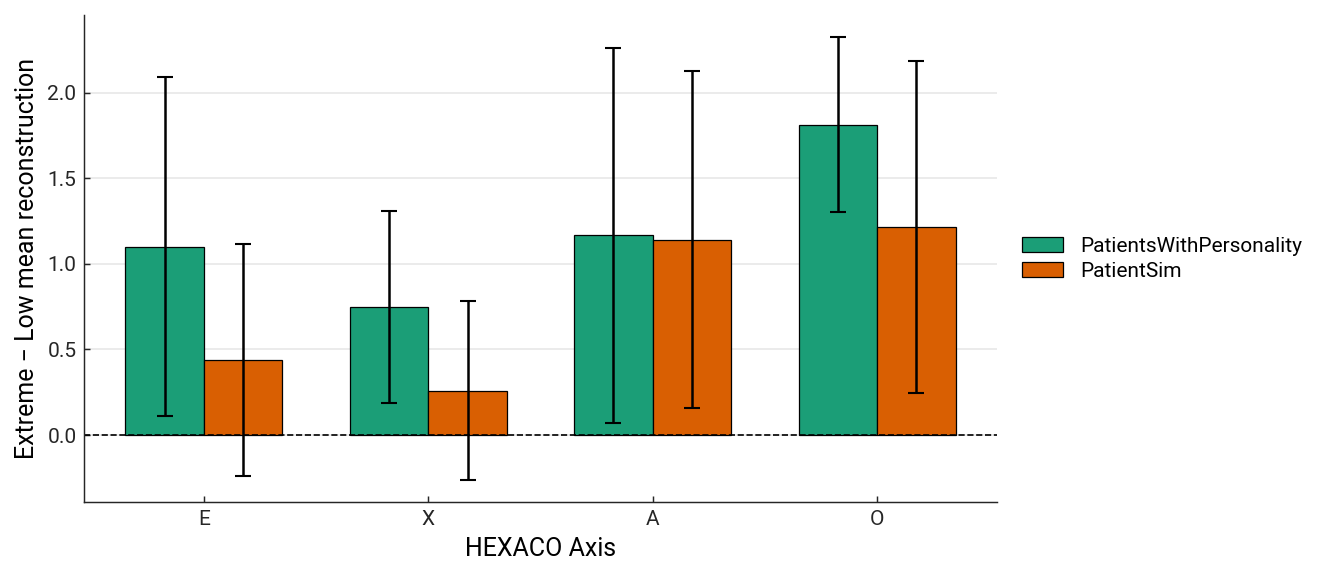

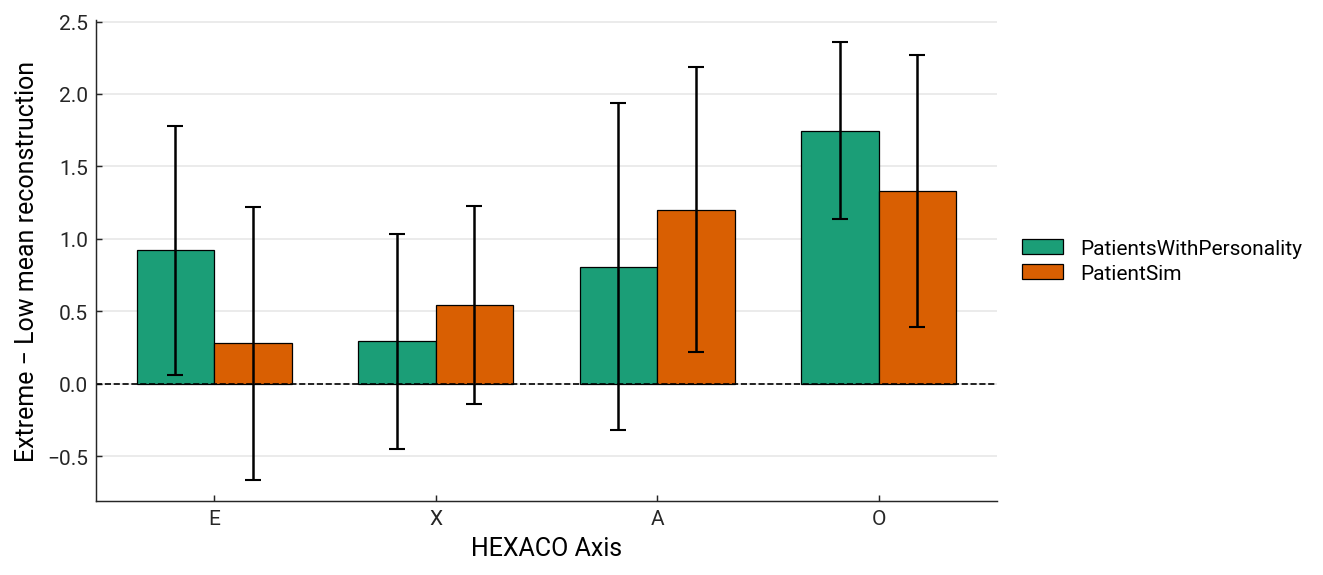

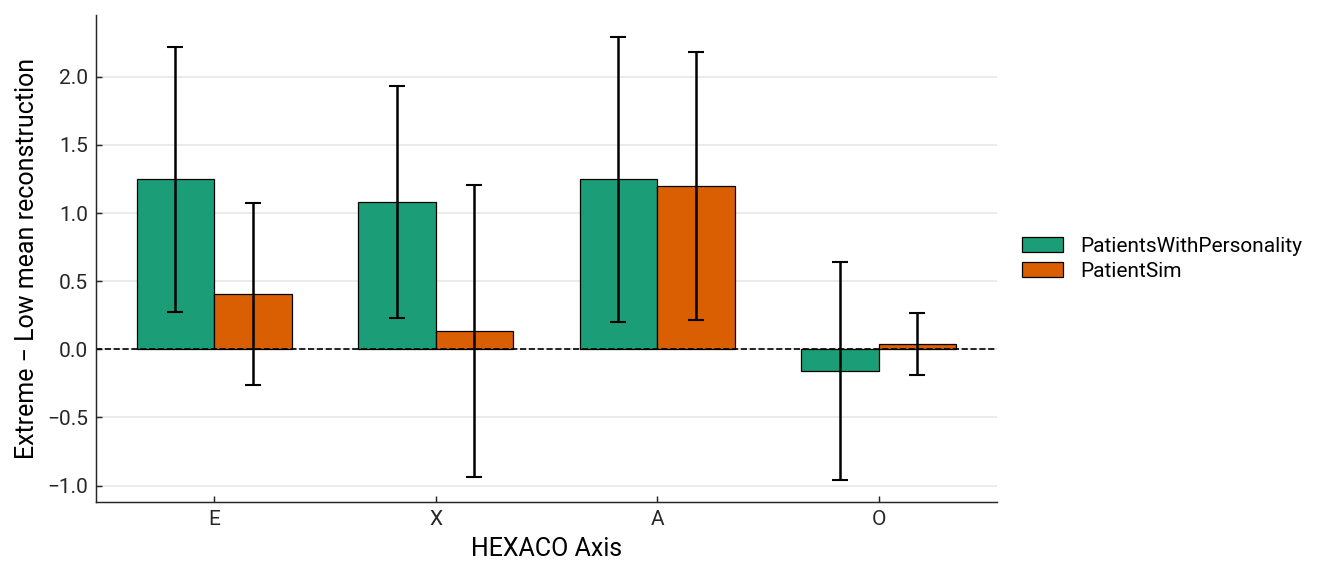

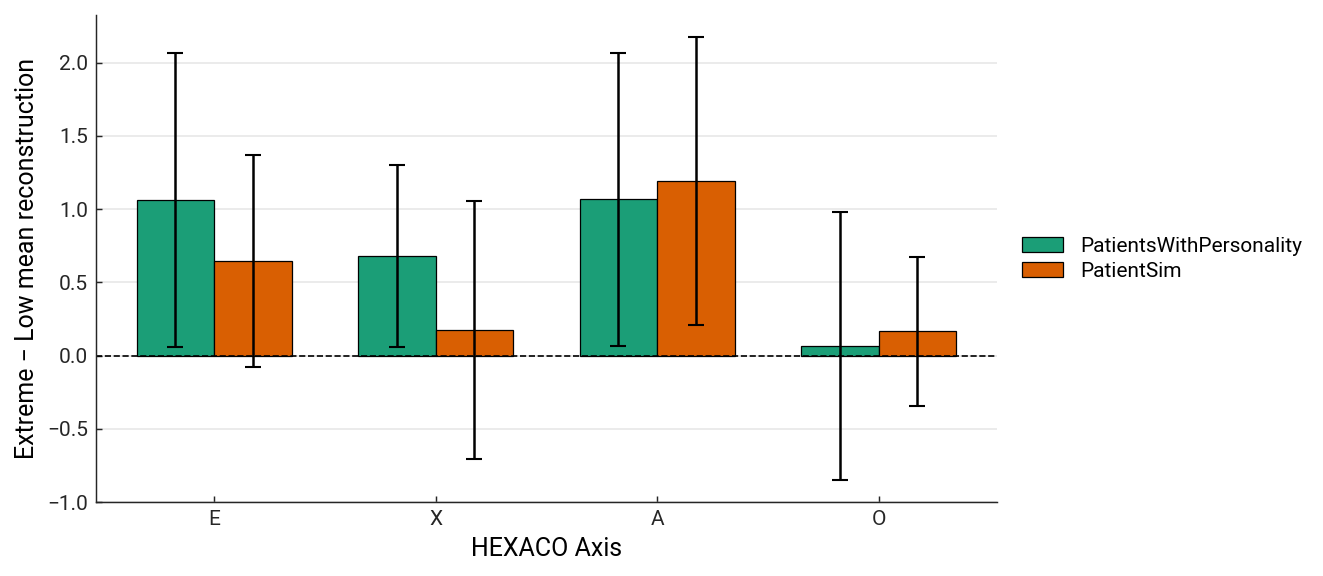

In [13]:
for variant in VARIANT_LABELS:
    for window in ("full", "turns_11_20"):
        plot_personality_extreme_difference(
            extremes[extremes["window"] == window],
            rater=variant,
            patient_type_col="simulator",
            axis_col="hexaco_axis",
            exclude_axes=["H", "C"],
            title=f"{VARIANT_LABELS[variant]} — {WINDOW_LABELS[window]}",
            show_sd=True,
        )

## 6. Independent judge

The paper's judge, Gemini 3.1 Flash-Lite, is also the conversational model and the model the latent-role prompt was tuned against. To rule out a same-model-family effect, the same 480 conversations (9 PWP and 7 PatientSim personas × 30 cases) are re-scored by **Claude Sonnet 5.5**, which plays no part in generation or prompt optimization (`scripts/run_personality_ablation.py --config-name personality_ablation_vha_judge_claude_sonnet_5_5`). Agreement on the full conversation, at the level the paper reports (mean reconstructed level per persona and axis) and per conversation.

In [14]:
claude_long = to_long(
    pd.read_csv(f"{ROOT}/personality_ablation_judge_claude_sonnet_5_5.csv")
)
judge_agreement(long, claude_long, window="full").round(3)

,prompt_variant,n_conversations,n_cells,persona_spearman,persona_pearson,persona_mae,within_one
0,anchored,480,96,0.915,0.922,0.214,0.989
1,neutral,480,96,0.877,0.855,0.284,0.980
